# Deep Learning - Assignment 1
### Training-Testing Neural Net with MNIST Dataset using PyTorch
#### Group No. 5

##### Task 1 - Install PyTorch

In [1]:
%pip install torch torchvision matplotlib

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   -------------------------------

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

PyTorch version: 2.14.1+cpu
Torchvision version: 0.29.1+cpu


##### Task 2 - Download and Load the Dataset

In [2]:
from torch.utils.data import random_split

# Convert images to tensors and normalize them
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Download and load MNIST
full_train = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_set   = torchvision.datasets.MNIST(root="./data", train=False, download=True, transform=transform)

# Split the 60,000 training images into 50,000 for training and 10,000 for validation
train_set, val_set = random_split(full_train, [50000, 10000],
                                  generator=torch.Generator().manual_seed(42))

# Create DataLoaders
batch_size = 32
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=batch_size, shuffle=False)

print("Dataset loaded successfully!")
print("Training images:  ", len(train_set))
print("Validation images:", len(val_set))
print("Test images:      ", len(test_set))

100%|██████████| 9.91M/9.91M [00:18<00:00, 550kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 153kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 851kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 1.51MB/s]

Dataset loaded successfully!
Training images:   50000
Validation images: 10000
Test images:       10000


##### Task 3 - Inspect the Dataset

In [3]:
# Get one batch from the training DataLoader
images, labels = next(iter(train_loader))

# Print the size of the image and label tensors
print("Images tensor size:", images.shape)
print("Labels tensor size:", labels.shape)
print("Single image size: ", images[0].shape)

Images tensor size: torch.Size([32, 1, 28, 28])
Labels tensor size: torch.Size([32])
Single image size:  torch.Size([1, 28, 28])


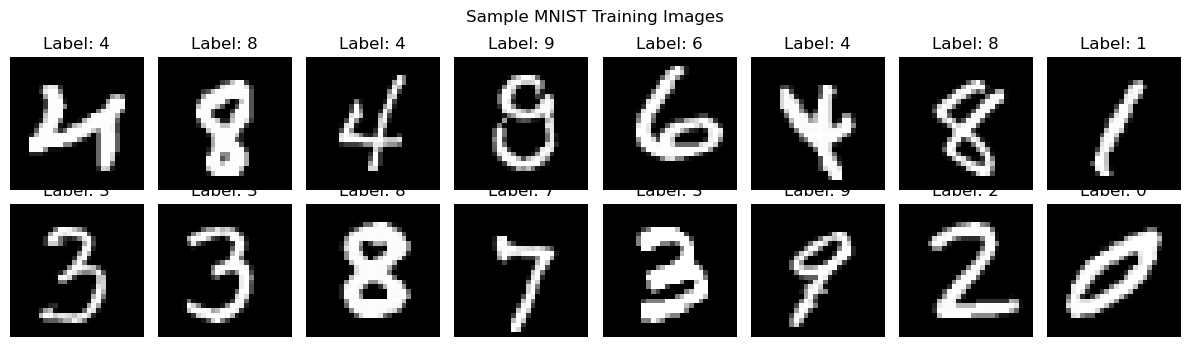

In [8]:
# Visualize the first 16 images in the batch with their labels
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")  # squeeze removes the channel dimension: [1, 28, 28] -> [28, 28]
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.suptitle("Sample MNIST Training Images")
plt.tight_layout()
plt.show()

##### Task 4 - Creating A Simple Network

In [9]:
class SimpleNet(nn.Module):
    def __init__(self, input_size=784, hidden_size=128, num_classes=10):
        super().__init__()
        # Fully connected layer: input -> hidden
        self.fc1 = nn.Linear(input_size, hidden_size)
        # ReLU activation (non-linearity)
        self.relu = nn.ReLU()
        # Fully connected layer: hidden -> output
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # Flatten from (N, 1, 28, 28) to (N, 784), keeping the batch dimension
        x = torch.flatten(x, 1)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)  # No softmax here: CrossEntropyLoss applies it internally
        return x

model = SimpleNet()
print(model)

SimpleNet(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [10]:
# Take one batch to verify the network works as required
images, labels = next(iter(train_loader))

print("Input shape before flatten:", images.shape)
print("Shape after flatten:       ", torch.flatten(images, 1).shape)

outputs = model(images)
print("Output shape:              ", outputs.shape)

# Count the trainable parameters
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Total trainable parameters:", total_params)

Input shape before flatten: torch.Size([32, 1, 28, 28])
Shape after flatten:        torch.Size([32, 784])
Output shape:               torch.Size([32, 10])
Total trainable parameters: 101770


##### Task 5 - Training Function

In [11]:
def train(net, dataloader, epochs=5, lr=0.01, momentum=0.9, print_every=200, verbose=True):
    # Loss function: applies softmax + negative log likelihood
    criterion = nn.CrossEntropyLoss()
    # Optimizer: stochastic gradient descent with learning rate and momentum
    optimizer = optim.SGD(net.parameters(), lr=lr, momentum=momentum)

    batch_losses = []   # loss of every mini-batch
    epoch_losses = []   # average loss per epoch
    epoch_accs = []     # accuracy per epoch

    net.train()  # put the network in training mode
    for epoch in range(epochs):
        running_loss, running_correct, running_total = 0.0, 0, 0
        epoch_loss_sum, epoch_correct, epoch_total = 0.0, 0, 0

        for batch_idx, (images, labels) in enumerate(dataloader, start=1):
            optimizer.zero_grad()              # 1. clear old gradients
            outputs = net(images)              # 2. forward pass
            loss = criterion(outputs, labels)  # 3. compute the loss
            loss.backward()                    # 4. backpropagation
            optimizer.step()                   # 5. update the weights

            # Track loss and accuracy
            batch_losses.append(loss.item())
            preds = outputs.argmax(dim=1)
            correct = (preds == labels).sum().item()

            running_loss += loss.item()
            running_correct += correct
            running_total += labels.size(0)
            epoch_loss_sum += loss.item()
            epoch_correct += correct
            epoch_total += labels.size(0)

            # Print debug information every `print_every` batches
            if verbose and batch_idx % print_every == 0:
                print(f"Epoch [{epoch+1}/{epochs}] | Batch [{batch_idx}/{len(dataloader)}] | "
                      f"Loss: {running_loss/print_every:.4f} | "
                      f"Accuracy: {100*running_correct/running_total:.2f}%")
                running_loss, running_correct, running_total = 0.0, 0, 0

        # Save epoch results
        epoch_losses.append(epoch_loss_sum / len(dataloader))
        epoch_accs.append(100 * epoch_correct / epoch_total)
        if verbose:
            print(f"==> Epoch {epoch+1} finished | Avg Loss: {epoch_losses[-1]:.4f} | "
                  f"Accuracy: {epoch_accs[-1]:.2f}%\n")

    return batch_losses, epoch_losses, epoch_accs